<a href="https://colab.research.google.com/github/egfuakye-resources08/2BSM-ScannerS-with-Lilith3/blob/main/ME_801_Assignment_4_Problem_2_SVM_Classifiers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Generated dataset X1: N = 100, seed = 0
-------------------------------------------------------
  n |       z_n1 |       z_n2 |       x_n1 |       x_n2
-------------------------------------------------------
  1 |   0.125730 |  -0.132105 |  -2.846013 |  -0.161795
  2 |   0.640423 |   0.104900 |  -2.215646 |   0.128476
  3 |  -0.535669 |   0.361595 |  -3.656058 |   0.442862
  4 |   1.304000 |   0.947081 |  -1.402933 |   1.159933
  5 |  -0.703735 |  -1.265421 |  -3.861896 |  -1.549818
  6 |  -0.623274 |   0.041326 |  -3.763352 |   0.050614
  7 |  -2.325031 |  -0.218792 |  -5.847570 |  -0.267964
  8 |  -1.245911 |  -0.732267 |  -4.525923 |  -0.896841
  9 |  -0.544259 |  -0.316300 |  -3.666578 |  -0.387387
 10 |   0.411631 |   1.042513 |  -2.495858 |   1.276813
 11 |  -0.128535 |   1.366463 |  -3.157422 |   1.673569
 12 |  -0.665195 |   0.351510 |  -3.814694 |   0.430510
 13 |   0.903470 |   0.094012 |  -1.893480 |   0.115141
 14 |  -0.743499 |  -0.921725 |  -3.910597 |  -1.128878
 15 |  

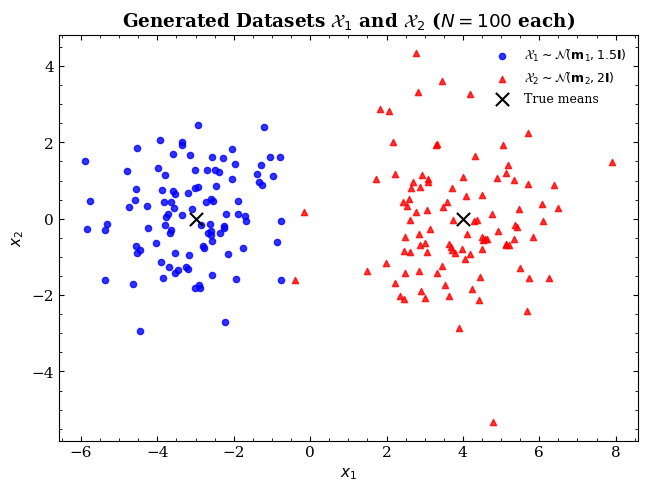

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Step 1: I set a seed so I can reproduce the results.
rng = np.random.default_rng(0)

# Step 2: I define the sample size, the means and the covariance matrices.
N = 100
I = np.eye(2)
m1, S1 = np.array([-3.0, 0.0]), 1.5 * I
m2, S2 = np.array([4.0, 0.0]), 2.0 * I

# Step 3: I compute the Cholesky factors, S = L L^T (here L = sigma I).
L1 = np.linalg.cholesky(S1)
L2 = np.linalg.cholesky(S2)

# Step 4: I draw standard normal vectors z ~ N(0, I) for each dataset.
z1 = rng.standard_normal((N, 2))
z2 = rng.standard_normal((N, 2))

# Step 5: I transform them, x = m + L z, so that x ~ N(m, S).
X1 = m1 + z1 @ L1.T
X2 = m2 + z2 @ L2.T

# Step 6: I print the generated vectors in a table.
headers = (
    f"{'n':>3} | {'z_n1':>10} | {'z_n2':>10} | "
    f"{'x_n1':>10} | {'x_n2':>10}"
)
separator = "-" * len(headers)
for name, Z, X in (("X1", z1, X1), ("X2", z2, X2)):
    print(f"\nGenerated dataset {name}: N = {N}, seed = 0")
    print(separator)
    print(headers)
    print(separator)
    for n, (zn, xn) in enumerate(zip(Z, X), start=1):
        print(
            f"{n:>3} | {zn[0]:>10.6f} | {zn[1]:>10.6f} | "
            f"{xn[0]:>10.6f} | {xn[1]:>10.6f}"
        )
    print(separator)
    print(f"Data shape: {X.shape}")

# Step 7: I compare the sample estimates with the true values.
headers = (
    f"{'set':>3} | {'m_1':>6} | {'m_2':>6} | {'m_hat_1':>8} | {'m_hat_2':>8} | "
    f"{'S_11':>5} | {'S_hat_11':>8} | {'S_hat_12':>8} | {'S_hat_22':>8} | {'SE':>6}"
)
separator = "-" * len(headers)
print("\nSample estimates vs true values")
print(separator)
print(headers)
print(separator)
for name, X, m, S in (("X1", X1, m1, S1), ("X2", X2, m2, S2)):
    m_hat = X.mean(axis=0)              # (1/N) sum x_n
    S_hat = np.cov(X, rowvar=False)     # 1/(N-1) sum (x_n - m_hat)(x_n - m_hat)^T
    se = np.sqrt(S[0, 0] / N)           # standard error of each mean coordinate, sigma/sqrt(N)
    print(
        f"{name:>3} | {m[0]:>6.2f} | {m[1]:>6.2f} | {m_hat[0]:>8.3f} | {m_hat[1]:>8.3f} | "
        f"{S[0, 0]:>5.2f} | {S_hat[0, 0]:>8.3f} | {S_hat[0, 1]:>8.3f} | {S_hat[1, 1]:>8.3f} | {se:>6.3f}"
    )
print(separator)
print(f"Distance between true means: {np.linalg.norm(m2 - m1):.1f}")

# Step 8: I plot both datasets and mark the true means.
BLUE, RED = "#0000FF", "#FF0000"
style = {
    "font.family": "serif",
    "font.size": 11,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
}
with plt.rc_context(style):
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(
        X1[:, 0], X1[:, 1],
        c=BLUE,
        marker="o",
        s=20,
        alpha=0.8,
        label=r"$\mathcal{X}_1 \sim \mathcal{N}(\mathbf{m}_1, 1.5\mathbf{I})$",
    )
    ax.scatter(
        X2[:, 0], X2[:, 1],
        c=RED,
        marker="^",
        s=20,
        alpha=0.8,
        label=r"$\mathcal{X}_2 \sim \mathcal{N}(\mathbf{m}_2, 2\mathbf{I})$",
    )
    ax.scatter(
        [m1[0], m2[0]], [m1[1], m2[1]],
        c="k",
        marker="x",
        s=90,
        label="True means",
    )
    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")
    ax.set_aspect("equal")
    ax.set_title(r"Generated Datasets $\mathcal{X}_1$ and $\mathcal{X}_2$ ($N=100$ each)", fontweight="bold")
    ax.legend(frameon=False, fontsize=9)
    fig.tight_layout()
    plt.show()
    plt.close(fig)

Training points: 140
Test points:     60
Training: X1 (+1) = 70, X2 (-1) = 70
Test: X1 (+1) = 30, X2 (-1) = 30

LINEAR GRID SEARCH
* = selected candidate
  Rank         C     gamma     CV accuracy           CV SD        CV hinge
*    1        10         -    0.9928571429    0.0142857143    0.0156303845
     2       100         -    0.9928571429    0.0142857143    0.0179381759
     3      1000         -    0.9928571429    0.0142857143    0.0179381759
     4         1         -    0.9928571429    0.0142857143    0.0284235222
     5       0.1         -    0.9928571429    0.0142857143    0.0715256985
     6      0.01         -    0.9928571429    0.0142857143    0.2933438381

RBF GRID SEARCH
* = selected candidate
  Rank         C     gamma     CV accuracy           CV SD        CV hinge
*    1       100      0.01    0.9928571429    0.0142857143    0.0229221331
     2        10       0.1    0.9928571429    0.0142857143    0.0310712570
     3        10      0.01    0.9928571429    0.01428571

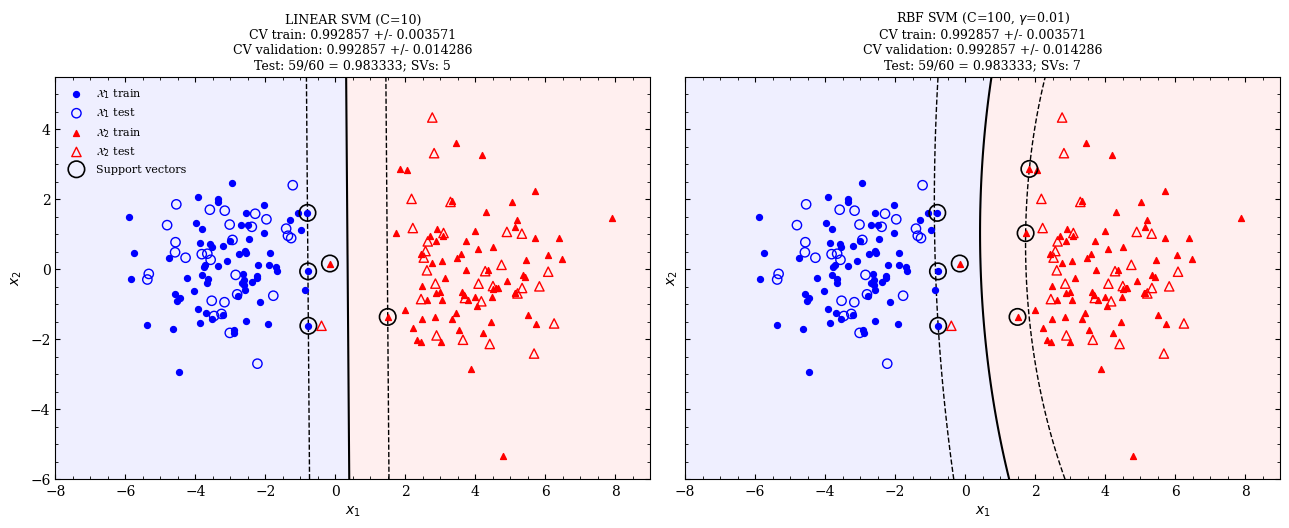


Outputs saved to: /content/svm_outputs


In [ ]:
from pathlib import Path
import csv

import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, hinge_loss, confusion_matrix
from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RepeatedStratifiedKFold,
)


# 1. Generate the datasets.
OUT = Path("svm_outputs")
OUT.mkdir(exist_ok=True)

SEED = 0
N = 100
rng = np.random.default_rng(SEED)

m1 = np.array([-3.0, 0.0])
m2 = np.array([4.0, 0.0])
S1 = 1.5 * np.eye(2)
S2 = 2.0 * np.eye(2)

z1 = rng.standard_normal((N, 2))
z2 = rng.standard_normal((N, 2))

X1 = m1 + z1 @ np.linalg.cholesky(S1).T
X2 = m2 + z2 @ np.linalg.cholesky(S2).T

X = np.vstack([X1, X2])
y = np.concatenate([
    np.ones(N, dtype=int),
    -np.ones(N, dtype=int),
])

point_ids = np.arange(1, len(X) + 1)


# 2. Create the stratified training/test split.
X_tr, X_te, y_tr, y_te, id_tr, id_te = train_test_split(
    X,
    y,
    point_ids,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)

print(f"Training points: {len(X_tr)}")
print(f"Test points:     {len(X_te)}")

for name, labels in [("Training", y_tr), ("Test", y_te)]:
    print(
        f"{name}: "
        f"X1 (+1) = {np.sum(labels == 1)}, "
        f"X2 (-1) = {np.sum(labels == -1)}"
    )


# 3. Use the same 50 validation splits for both kernels.
cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=SEED,
)

splits = list(cv.split(X_tr, y_tr))
R = len(splits)


# 4. Define the scores and original selection rule.
def neg_hinge(estimator, X_val, y_val):
    scores = estimator.decision_function(X_val)
    return -hinge_loss(y_val, scores, labels=[-1, 1])


def select_best(results):
    accuracy = np.asarray(results["mean_test_acc"])
    ties = np.flatnonzero(
        np.isclose(accuracy, accuracy.max())
    )
    negative_hinge = np.asarray(
        results["mean_test_hinge"]
    )
    return int(ties[np.argmax(negative_hinge[ties])])


scoring = {
    "acc": "accuracy",
    "hinge": neg_hinge,
}

C_grid = [0.01, 0.1, 1, 10, 100, 1000]

grids = {
    "linear": {
        "svm__C": C_grid,
    },
    "rbf": {
        "svm__C": C_grid,
        "svm__gamma": [0.01, 0.1, 1, 10, 100],
    },
}


# 5. Fit both grid searches.
models = {}

for kernel, grid in grids.items():
    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("svm", SVC(kernel=kernel)),
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=grid,
        cv=splits,
        scoring=scoring,
        refit=select_best,
        return_train_score=True,
        error_score="raise",
        n_jobs=-1,
    )

    search.fit(X_tr, y_tr)
    models[kernel] = search


def write_csv(filename, rows):
    if not rows:
        return

    with (OUT / filename).open(
        "w", newline="", encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(
            file, fieldnames=list(rows[0])
        )
        writer.writeheader()
        writer.writerows(rows)


# 6. Print and save the complete search results.
grid_rows = []

for kernel, search in models.items():
    results = search.cv_results_

    order = np.lexsort((
        -np.asarray(results["mean_test_hinge"]),
        -np.asarray(results["mean_test_acc"]),
    ))

    print(f"\n{'=' * 94}")
    print(f"{kernel.upper()} GRID SEARCH")
    print("* = selected candidate")
    print(
        f"{'':1} {'Rank':>4} {'C':>9} {'gamma':>9} "
        f"{'CV accuracy':>15} {'CV SD':>15} {'CV hinge':>15}"
    )

    for rank, index in enumerate(order, start=1):
        params = results["params"][index]
        C = params["svm__C"]
        gamma = params.get("svm__gamma", "-")
        selected = int(index) == search.best_index_

        print(
            f"{'*' if selected else ' ':1} "
            f"{rank:>4} {C:>9g} {str(gamma):>9} "
            f"{results['mean_test_acc'][index]:>15.10f} "
            f"{results['std_test_acc'][index]:>15.10f} "
            f"{-results['mean_test_hinge'][index]:>15.10f}"
        )

        grid_rows.append({
            "kernel": kernel,
            "rank": rank,
            "selected": selected,
            "C": C,
            "gamma": gamma,
            "cv_accuracy": results["mean_test_acc"][index],
            "cv_accuracy_sd": results["std_test_acc"][index],
            "cv_hinge": -results["mean_test_hinge"][index],
        })

write_csv("grid_search.csv", grid_rows)


# 7. Evaluate the selected refitted classifiers.
evaluation = {}
summary_rows = []
support_rows = []

for kernel, search in models.items():
    best = search.best_estimator_
    svm = best["svm"]
    results = search.cv_results_
    index = search.best_index_

    pred_train = best.predict(X_tr)
    pred_test = best.predict(X_te)
    score_train = best.decision_function(X_tr)
    score_test = best.decision_function(X_te)

    cm = confusion_matrix(
        y_te, pred_test, labels=[-1, 1]
    )
    tn, fp, fn, tp = cm.ravel()

    evaluation[kernel] = {
        "pred_train": pred_train,
        "pred_test": pred_test,
        "score_train": score_train,
        "score_test": score_test,
    }

    summary = {
        "kernel": kernel,
        "C": search.best_params_["svm__C"],
        "gamma": search.best_params_.get("svm__gamma", "-"),
        "cv_train_accuracy": results["mean_train_acc"][index],
        "cv_train_sd": results["std_train_acc"][index],
        "cv_validation_accuracy": results["mean_test_acc"][index],
        "cv_validation_sd": results["std_test_acc"][index],
        "cv_validation_hinge": -results["mean_test_hinge"][index],
        "refit_train_accuracy": accuracy_score(y_tr, pred_train),
        "test_accuracy": accuracy_score(y_te, pred_test),
        "test_hinge": hinge_loss(
            y_te, score_test, labels=[-1, 1]
        ),
        "support_vectors": int(svm.n_support_.sum()),
        "TP": int(tp),
        "FN": int(fn),
        "FP": int(fp),
        "TN": int(tn),
    }
    summary_rows.append(summary)

    print(f"\n{'=' * 72}")
    print(f"{kernel.upper()} — SELECTED CLASSIFIER")
    print("Hyperparameters:", search.best_params_)

    print(
        "CV training accuracy:   "
        f"{summary['cv_train_accuracy']:.12f} "
        f"+/- {summary['cv_train_sd']:.12f}"
    )
    print(
        "CV validation accuracy: "
        f"{summary['cv_validation_accuracy']:.12f} "
        f"+/- {summary['cv_validation_sd']:.12f}"
    )
    print(
        "CV validation hinge:    "
        f"{summary['cv_validation_hinge']:.12f}"
    )
    print(
        "Final-refit train acc:  "
        f"{summary['refit_train_accuracy']:.12f}"
    )
    print(
        "Test accuracy:          "
        f"{summary['test_accuracy']:.12f} "
        f"({np.sum(pred_test == y_te)}/{len(y_te)})"
    )
    print(
        "Test hinge loss:        "
        f"{summary['test_hinge']:.12f}"
    )
    print("Class order:", svm.classes_)
    print("Support vectors per class:", svm.n_support_)
    print("Total support vectors:", summary["support_vectors"])

    print("Confusion matrix: rows=true, columns=predicted")
    print("Class order: [-1, +1]")
    print(cm)
    print(f"TP={tp}, FN={fn}, FP={fp}, TN={tn}")

    for j, local_index in enumerate(svm.support_):
        support_rows.append({
            "kernel": kernel,
            "point_id": int(id_tr[local_index]),
            "x1": X_tr[local_index, 0],
            "x2": X_tr[local_index, 1],
            "label": int(y_tr[local_index]),
            "signed_dual_coefficient": svm.dual_coef_[0, j],
            "alpha": abs(svm.dual_coef_[0, j]),
        })

write_csv("selected_models.csv", summary_rows)
write_csv("support_vectors.csv", support_rows)


# 8. Keep numerical diagnostics without additional plots.
point_rows = []

print(f"\n{'=' * 72}")
print("DIRECT COMPARISON")

for split_name, XX, yy, ids in [
    ("train", X_tr, y_tr, id_tr),
    ("test", X_te, y_te, id_te),
]:
    pL = evaluation["linear"][f"pred_{split_name}"]
    pR = evaluation["rbf"][f"pred_{split_name}"]
    sL = evaluation["linear"][f"score_{split_name}"]
    sR = evaluation["rbf"][f"score_{split_name}"]

    print(f"\n{split_name.upper()}")
    print(
        "Identical predictions:",
        np.array_equal(pL, pR),
    )
    print(
        "Prediction disagreements:",
        int(np.sum(pL != pR)),
    )
    print(
        "Exactly identical scores:",
        np.array_equal(sL, sR),
    )
    print(
        "Maximum absolute score difference:",
        f"{np.max(np.abs(sL - sR)):.12f}",
    )

    for kernel, predictions in [
        ("linear", pL),
        ("rbf", pR),
    ]:
        errors = np.flatnonzero(predictions != yy)
        print(f"{kernel.upper()} misclassified point IDs:",
              ids[errors].tolist())

        for j in errors:
            print(
                f"  ID={ids[j]}, "
                f"x=({XX[j, 0]:.8f}, {XX[j, 1]:.8f}), "
                f"true={yy[j]:+d}, "
                f"predicted={predictions[j]:+d}"
            )

    for j in range(len(XX)):
        point_rows.append({
            "split": split_name,
            "point_id": int(ids[j]),
            "x1": XX[j, 0],
            "x2": XX[j, 1],
            "true_label": int(yy[j]),
            "linear_prediction": int(pL[j]),
            "rbf_prediction": int(pR[j]),
            "linear_score": sL[j],
            "rbf_score": sR[j],
        })

write_csv("point_predictions.csv", point_rows)


# 9. Save and compare the selected candidates' fold scores.
fold_rows = []

for split_index in range(R):
    row = {
        "split": split_index + 1,
        "repeat": split_index // 5 + 1,
        "fold": split_index % 5 + 1,
    }

    for kernel, search in models.items():
        results = search.cv_results_
        index = search.best_index_

        row[f"{kernel}_train_accuracy"] = (
            results[f"split{split_index}_train_acc"][index]
        )
        row[f"{kernel}_validation_accuracy"] = (
            results[f"split{split_index}_test_acc"][index]
        )
        row[f"{kernel}_validation_hinge"] = (
            -results[f"split{split_index}_test_hinge"][index]
        )

    fold_rows.append(row)

write_csv("fold_comparison.csv", fold_rows)

print(f"\n{'=' * 72}")
print("FOLD-SCORE COMPARISON")

for metric in [
    "train_accuracy",
    "validation_accuracy",
    "validation_hinge",
]:
    left = np.array([
        row[f"linear_{metric}"] for row in fold_rows
    ])
    right = np.array([
        row[f"rbf_{metric}"] for row in fold_rows
    ])

    print(
        f"{metric}: "
        f"exactly equal = {np.array_equal(left, right)}; "
        f"maximum difference = "
        f"{np.max(np.abs(left - right)):.12f}"
    )


# 10. Create ONLY the linear and RBF plots.
BLUE = "#0000FF"
RED = "#FF0000"

style = {
    "font.family": "serif",
    "font.size": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.minor.visible": True,
    "ytick.minor.visible": True,
}

g1, g2 = np.meshgrid(
    np.linspace(-8, 9, 400),
    np.linspace(-6, 5.5, 300),
)
grid_points = np.c_[g1.ravel(), g2.ravel()]


def draw_points(ax):
    for label, color, marker, class_name in [
        (1, BLUE, "o", r"$\mathcal{X}_1$"),
        (-1, RED, "^", r"$\mathcal{X}_2$"),
    ]:
        train_mask = y_tr == label
        test_mask = y_te == label

        ax.scatter(
            X_tr[train_mask, 0],
            X_tr[train_mask, 1],
            c=color,
            marker=marker,
            s=18,
            label=f"{class_name} train",
            zorder=3,
        )
        ax.scatter(
            X_te[test_mask, 0],
            X_te[test_mask, 1],
            facecolors="none",
            edgecolors=color,
            marker=marker,
            s=45,
            label=f"{class_name} test",
            zorder=3,
        )

    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")
    ax.set_xlim(-8, 9)
    ax.set_ylim(-6, 5.5)
    ax.set_aspect("equal")


def setting_text(search):
    params = search.best_params_
    text = f"C={params['svm__C']:g}"

    if "svm__gamma" in params:
        text += rf", $\gamma$={params['svm__gamma']:g}"

    return text


with plt.rc_context(style):
    fig, axes = plt.subplots(
        1, 2, figsize=(13, 6), sharex=True, sharey=True
    )

    for ax, (kernel, search) in zip(axes, models.items()):
        best = search.best_estimator_
        results = search.cv_results_
        index = search.best_index_

        scores = best.decision_function(
            grid_points
        ).reshape(g1.shape)

        # Positive scores: blue; negative scores: red.
        regions = (scores >= 0).astype(int)

        ax.contourf(
            g1,
            g2,
            regions,
            levels=[-0.5, 0.5, 1.5],
            colors=["#FFE5E5", "#E5E5FF"],
            alpha=0.6,
            zorder=0,
        )

        ax.contour(
            g1,
            g2,
            scores,
            levels=[-1, 0, 1],
            colors="black",
            linestyles=["--", "-", "--"],
            linewidths=[1, 1.5, 1],
            zorder=2,
        )

        draw_points(ax)

        support_vectors = X_tr[best["svm"].support_]

        ax.scatter(
            support_vectors[:, 0],
            support_vectors[:, 1],
            s=140,
            facecolors="none",
            edgecolors="black",
            linewidths=1.2,
            label="Support vectors",
            zorder=4,
        )

        correct = int(np.sum(
            evaluation[kernel]["pred_test"] == y_te
        ))

        ax.set_title(
            f"{kernel.upper()} SVM ({setting_text(search)})\n"
            f"CV train: "
            f"{results['mean_train_acc'][index]:.6f}"
            f" +/- {results['std_train_acc'][index]:.6f}\n"
            f"CV validation: "
            f"{results['mean_test_acc'][index]:.6f}"
            f" +/- {results['std_test_acc'][index]:.6f}\n"
            f"Test: {correct}/{len(y_te)}"
            f" = {correct / len(y_te):.6f}; "
            f"SVs: {len(support_vectors)}",
            fontsize=9,
        )

    axes[0].legend(
        frameon=False,
        fontsize=8,
        loc="upper left",
    )

    fig.tight_layout()

    fig.savefig(
        OUT / "svm_two_kernels.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        OUT / "svm_two_kernels.pdf",
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

print(f"\nOutputs saved to: {OUT.resolve()}")

In [ ]:
!jupyter nbconvert --to html "/content/ME_801_Assignment_3_Problem_2_SVM_Classifiers.ipynb"

[NbConvertApp] Converting notebook /content/ME_801_Assignment_3_Problem_2_SVM_Classifiers.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 580299 bytes to /content/ME_801_Assignment_3_Problem_2_SVM_Classifiers.html
